# EEG entropy features and binary classification

This notebook follows the report's three independent binary tasks:

- Mumtaz: control vs depression
- Borisov: control vs schizophrenia
- Sakib: control vs anxiety

It computes or loads entropy measures and compares classifiers in two ways: a participant-level baseline (one row per participant) and window-level samples with nested-CV hyperparameter tuning, including XGBoost and LightGBM. Splits are always made at participant level to avoid leakage. Results are exploratory because `entropy_features.py` bounds each signal before calculation.

Restart the kernel and run from the first cell to enable optional RAPIDS `cuml.accel` before importing scikit-learn. It reports whether each supported operation runs on GPU or falls back to CPU. XGBoost and LightGBM independently test their GPU backends and fall back to CPU if unavailable. GPU training requires compatible NVIDIA drivers and GPU-enabled installations of RAPIDS, XGBoost 2.0+, and LightGBM; feature extraction and LDA remain CPU-based. Set `N_JOBS` to the allocated CPU cores; GPU searches run one fit at a time. GPU failures after startup are reported rather than silently retried.

On Valeria, use a GPU session and the course environment, or follow the [RAPIDS installation guide](https://docs.nvidia.com/datascience/install/) and [LightGBM installation guide](https://lightgbm.readthedocs.io/en/latest/Installation-Guide.html) for a compatible GPU build. Check the startup messages and RAPIDS logs to confirm what actually runs on GPU; a GPU session alone is not enough. Keep GPU memory use within Valeria's limits.

**Methodology change:** random forests are unweighted on both CPU and GPU, and the baseline SVM uses three-fold probability calibration instead of `SVC(probability=True)`. Results are not directly comparable with earlier runs.


In [1]:
%pip install numpy pandas scipy joblib lightgbm mne PyWavelets EntropyHub
%pip install --user --no-index "matplotlib==3.11.1"
%pip install --user --no-index "scipy==1.18.1"
%pip install --no-index "shap==0.51.0" "scikit-learn>=1.6,<1.8"
%pip install --no-index "xgboost==3.2.0"

Defaulting to user installation because normal site-packages is not writeable
Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
Note: you may need to restart the kernel to use updated packages.
Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
Note: you may need to restart the kernel to use updated packages.
Looking in links: /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/x86-64-v3, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/gentoo2023/generic, /cvmfs/soft.computecanada.ca/custom/python/wheelhouse/generic
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation be

In [2]:
from pathlib import Path
import sys

ROOT = Path.cwd()
if not (ROOT / 'entropy_features.py').exists():
    ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from gpu_setup import enable_cuml_accel
CUML_ACCEL_ENABLED = enable_cuml_accel()

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, balanced_accuracy_score,
    f1_score, precision_score, recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

OUTPUTS = ROOT / 'outputs'
OUTPUTS.mkdir(exist_ok=True)
print(ROOT)

from model_tuning import xgboost_device, lightgbm_device
XGB_DEVICE = xgboost_device()
LGBM_DEVICE = lightgbm_device()


RAPIDS cuML is not installed; scikit-learn models will use CPU.
/home/ulaval.ca/kebel33/ProjetMLSP
XGBoost GPU available: cuda:0


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


LightGBM GPU available: cuda


## Load entropy features

If `outputs/entropy_features.csv` does not exist, the cell below runs `entropy_features.py` to create it. This can take a while; later runs reuse the saved CSV.


In [3]:
import subprocess

FEATURE_FILE = OUTPUTS / 'entropy_features.csv'
if not FEATURE_FILE.exists():
    print(f'{FEATURE_FILE} not found; running entropy_features.py (this may take a while)...')
    subprocess.run([sys.executable, str(ROOT / 'entropy_features.py'), '--dataset', 'all',
                    '--output', str(FEATURE_FILE)], cwd=ROOT, check=True)

def drop_duplicate_participants(frame, order_by):
    """Drop participants whose feature values are identical to an earlier participant of the same dataset.

    Some source recordings are byte-identical copies (Mumtaz H S27 = H S30, MDD S33 = MDD S34).
    Keeping both would put the same EEG in the training and test folds."""
    value_columns = [c for c in frame.select_dtypes('number').columns if c not in ('label', 'window')]
    seen, drop = {}, []
    for (dataset, subject), rows in frame.groupby(['dataset', 'subject_id'], sort=False):
        key = (dataset, rows.sort_values(order_by)[value_columns].round(8).to_numpy().tobytes())
        if key in seen:
            drop.append(subject)
            print(f'{dataset}: {subject} duplicates {seen[key]}; removed')
        else:
            seen[key] = subject
    return frame[~frame.subject_id.isin(drop)].reset_index(drop=True)

channel_features = drop_duplicate_participants(pd.read_csv(FEATURE_FILE), ['channel'])
with pd.option_context('display.max_rows', None):
    display(channel_features)


,dataset,subject_id,label,channel,sample_entropy,dispersion_entropy,fuzzy_entropy,shannon_entropy,lz_complexity
0,mumtaz,H_S1_EC,0,0,1.635822,4.238579,1.714918,1.771904,1.089844
1,mumtaz,H_S1_EC,0,1,1.671819,4.274347,1.776490,1.886936,1.107422
2,mumtaz,H_S1_EC,0,2,1.728227,4.335399,1.838867,1.940190,1.089844
3,mumtaz,H_S1_EC,0,3,1.986043,4.465918,2.006268,2.189694,1.072266
4,mumtaz,H_S1_EC,0,4,1.991807,4.481854,2.058141,2.291724,1.125000
5,mumtaz,H_S1_EC,0,5,2.175567,4.478098,2.073650,2.330930,1.054688
6,mumtaz,H_S1_EC,0,6,1.885099,4.344467,1.961008,2.356328,1.107422
7,mumtaz,H_S1_EC,0,7,2.191510,4.504646,2.143411,2.786478,1.125000
8,mumtaz,H_S1_EC,0,8,2.114617,4.478388,2.180469,2.770352,1.107422
9,mumtaz,H_S1_EC,0,9,2.200802,4.523627,2.145868,2.753352,1.089844


## Aggregate channels into participant-level rows

Each participant gets one row. A feature is named `measure_channel_N`. Keeping participants intact prevents channel/window leakage.


In [4]:
MEASURES = ['sample_entropy', 'dispersion_entropy', 'fuzzy_entropy',
            'shannon_entropy', 'lz_complexity']

def to_participant_rows(frame):
    required = {'dataset', 'subject_id', 'label', 'channel', *MEASURES}
    missing = required.difference(frame.columns)
    if missing:
        raise ValueError(f'Missing columns: {sorted(missing)}')
    wide = frame.pivot_table(index=['dataset', 'subject_id', 'label'],
                             columns='channel', values=MEASURES, aggfunc='first')
    wide.columns = [f'{measure}_channel_{channel}' for measure, channel in wide.columns]
    return wide.reset_index()

participant_features = to_participant_rows(channel_features)
participant_features.to_csv(OUTPUTS / 'participant_entropy_features.csv', index=False)
participant_features.groupby(['dataset', 'label']).size()


dataset  label
borisov  0        39
         1        45
mumtaz   0        27
         1        29
sakib    0        15
         1        23
dtype: int64

In [5]:
TASK_NAMES = {
    'mumtaz': 'control vs depression',
    'borisov': 'control vs schizophrenia',
    'sakib': 'control vs anxiety',
}
for dataset, task in TASK_NAMES.items():
    subset = participant_features[participant_features.dataset == dataset]
    print(dataset, task)
    print(subset.label.value_counts().sort_index().rename(index={0: 'control', 1: 'disease'}))


mumtaz control vs depression
label
control    27
disease    29
Name: count, dtype: int64
borisov control vs schizophrenia
label
control    39
disease    45
Name: count, dtype: int64
sakib control vs anxiety
label
control    15
disease    23
Name: count, dtype: int64


## Compare models with participant-level cross-validation

Every preprocessing step is inside a pipeline and is fitted separately in each training fold. `StratifiedGroupKFold` keeps all rows from one participant together; this remains safe if window-level rows are added later. Out-of-fold predictions use every participant exactly once for evaluation.


In [6]:
MODELS = {
    'logistic_regression': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LogisticRegression(class_weight='balanced', max_iter=3000, random_state=42)),
    ]),
    'svm': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', CalibratedClassifierCV(
            estimator=SVC(class_weight='balanced', random_state=42), cv=3, ensemble=False)),
    ]),
    'random_forest': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(
            n_estimators=300, random_state=42, n_jobs=-1)),
    ]),
    'lda': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scale', StandardScaler()),
        ('model', LinearDiscriminantAnalysis()),
    ]),
    'xgboost': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=3, subsample=0.8,
                                colsample_bytree=0.5, eval_metric='logloss', random_state=42, n_jobs=1,
                                tree_method='hist', device=XGB_DEVICE)),
    ]),
    'lightgbm': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', LGBMClassifier(n_estimators=100, learning_rate=0.1, num_leaves=4, min_child_samples=5,
                                 subsample=0.8, subsample_freq=1, colsample_bytree=0.5,
                                 class_weight='balanced', random_state=42, n_jobs=1, verbose=-1,
                                 device_type=LGBM_DEVICE)),
    ]),
}

def evaluate_task(dataset):
    subset = participant_features[participant_features.dataset == dataset].dropna(axis=1, how='all')
    feature_columns = [c for c in subset if c not in {'dataset', 'subject_id', 'label'}]
    X = subset[feature_columns].replace([np.inf, -np.inf], np.nan)
    y = subset.label.astype(int)
    groups = subset.subject_id
    n_splits = min(5, int(y.value_counts().min()))
    if n_splits < 2:
        raise ValueError(f'{dataset} needs at least two participants per class')
    cv = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=42)
    rows, fitted, prediction_rows = [], {}, []
    for name, estimator in MODELS.items():
        all_true, all_pred, all_prob = [], [], []
        all_subjects = []
        for train_idx, test_idx in cv.split(X, y, groups):
            model = clone(estimator)
            model.fit(X.iloc[train_idx], y.iloc[train_idx])
            probability = model.predict_proba(X.iloc[test_idx])[:, 1]
            prediction = model.predict(X.iloc[test_idx])
            all_true.extend(y.iloc[test_idx].to_numpy())
            all_pred.extend(prediction)
            all_prob.extend(probability)
            all_subjects.extend(subset.iloc[test_idx].subject_id)
        y_true = np.asarray(all_true)
        y_pred = np.asarray(all_pred)
        y_prob = np.asarray(all_prob)
        rows.append({'dataset': dataset, 'task': TASK_NAMES[dataset], 'model': name,
            'n_participants': len(y_true), 'n_folds': n_splits,
            'balanced_accuracy': balanced_accuracy_score(y_true, y_pred),
            'precision': precision_score(y_true, y_pred, zero_division=0),
            'recall': recall_score(y_true, y_pred, zero_division=0),
            'f1': f1_score(y_true, y_pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, y_prob)})
        fitted[name] = (y_true, y_pred, y_prob)
        prediction_rows.extend(
            {'dataset': dataset, 'subject_id': subject, 'model': name,
             'label': label, 'prediction': pred, 'probability': prob}
            for subject, label, pred, prob in zip(all_subjects, y_true, y_pred, y_prob)
        )
    return pd.DataFrame(rows), fitted, pd.DataFrame(prediction_rows)

results, evaluation_data, prediction_frames = [], {}, []
for dataset in TASK_NAMES:
    task_results, task_evaluation, task_predictions = evaluate_task(dataset)
    results.append(task_results)
    evaluation_data[dataset] = task_evaluation
    prediction_frames.append(task_predictions)
metrics = pd.concat(results, ignore_index=True)
predictions = pd.concat(prediction_frames, ignore_index=True)
metrics.to_csv(OUTPUTS / 'classification_metrics.csv', index=False)
predictions.to_csv(OUTPUTS / 'classification_predictions.csv', index=False)
metrics.sort_values(['dataset', 'balanced_accuracy'], ascending=[True, False])


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/xgboost/core.py:751: UserWarning: [08:29:16] WARNING: /tmp/build_wheels_tmp.45258/python-3.11/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)
/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/utils/deprecation.py:132: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be r

,dataset,task,model,n_participants,n_folds,balanced_accuracy,precision,recall,f1,roc_auc
11,borisov,control vs schizophrenia,lightgbm,84,5,0.647863,0.702703,0.577778,0.634146,0.624501
7,borisov,control vs schizophrenia,svm,84,5,0.647009,0.653846,0.755556,0.701031,0.646724
10,borisov,control vs schizophrenia,xgboost,84,5,0.618803,0.651163,0.622222,0.636364,0.647293
8,borisov,control vs schizophrenia,random_forest,84,5,0.615385,0.638298,0.666667,0.652174,0.629060
9,borisov,control vs schizophrenia,lda,84,5,0.578632,0.604167,0.644444,0.623656,0.597151
6,borisov,control vs schizophrenia,logistic_regression,84,5,0.545299,0.577778,0.577778,0.577778,0.613675
2,mumtaz,control vs depression,random_forest,56,5,0.781609,0.742857,0.896552,0.812500,0.848020
4,mumtaz,control vs depression,xgboost,56,5,0.747126,0.727273,0.827586,0.774194,0.780332
0,mumtaz,control vs depression,logistic_regression,56,5,0.745849,0.714286,0.862069,0.781250,0.796935
5,mumtaz,control vs depression,lightgbm,56,5,0.728608,0.705882,0.827586,0.761905,0.791826


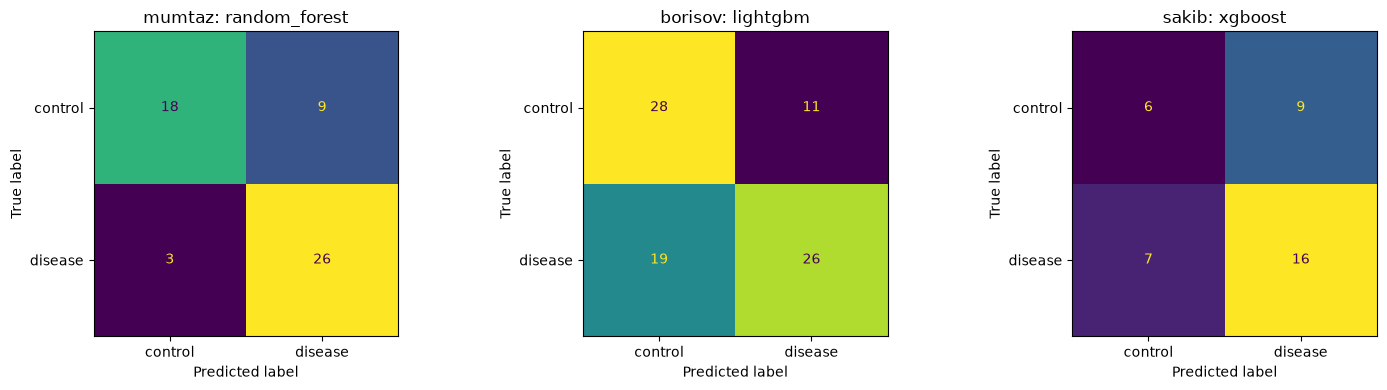

In [7]:
fig, axes = plt.subplots(1, len(TASK_NAMES), figsize=(15, 4))
for ax, dataset in zip(axes, TASK_NAMES):
    best = metrics[metrics.dataset == dataset].sort_values(
        'balanced_accuracy', ascending=False).iloc[0].model
    y_true, y_pred, y_prob = evaluation_data[dataset][best]
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=['control', 'disease'], ax=ax, colorbar=False)
    ax.set_title(f'{dataset}: {best}')
plt.tight_layout()
plt.show()


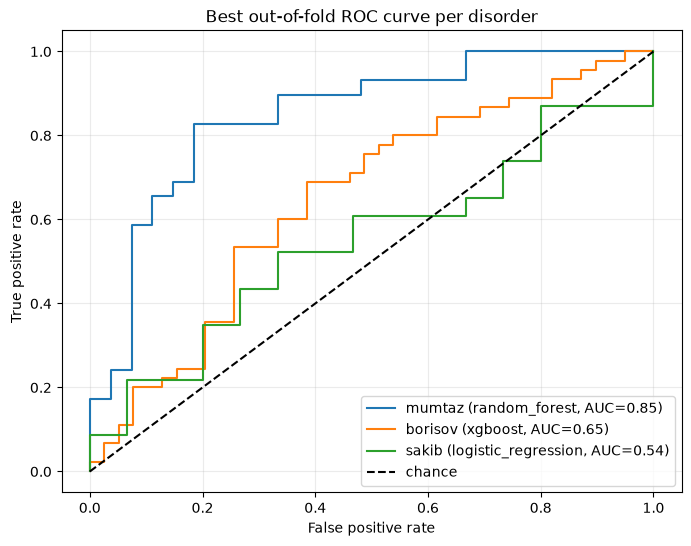

In [8]:
plt.figure(figsize=(8, 6))
for dataset in TASK_NAMES:
    best = metrics[metrics.dataset == dataset].sort_values('roc_auc', ascending=False).iloc[0].model
    y_true, y_pred, y_prob = evaluation_data[dataset][best]
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    auc = roc_auc_score(y_true, y_prob)
    plt.plot(fpr, tpr, label=f'{dataset} ({best}, AUC={auc:.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Best out-of-fold ROC curve per disorder')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


The baseline metrics above are out-of-fold estimates from one fixed five-fold partition with default hyperparameters and one row per participant. They are kept as a reference for the window-level analysis below. This part saves `participant_entropy_features.csv`, `classification_metrics.csv`, and `classification_predictions.csv` under `outputs/`.


## Window-level samples and tuned models

The baseline above uses one row per participant, which leaves only 38-84 training rows per task. Here each participant's EEG is cut into 10 s windows (`extract_entropy.py`), decomposed into delta/theta/alpha/beta/gamma with a DWT, and SampEn, DispEn, FuzzyEn and Shannon entropy are computed per channel and band. `extract_extra_features.py` adds, on the same windows and bands, the approximate and permutation entropies of Li et al. (2024), Lempel-Ziv complexity, and log/relative band power (switch with `USE_EXTRA_FEATURES`). Each window becomes one training sample.

- All windows of a participant stay in the same fold (`StratifiedGroupKFold` on `subject_id`).
- Each disorder is a separate task: models are trained and tested on one dataset at a time, never on pooled datasets.
- Duplicate recordings (identical copies of the same EEG under different IDs) are removed before modelling.
- Hyperparameters are chosen by **nested cross-validation** (`model_tuning.py`): a randomized search (scored by ROC AUC) inside a grouped inner CV runs only on the outer training participants, so the outer test participants are never used for tuning. The search also tunes the in-fold feature selection (top 10/25/50/100 % by ANOVA F), which matters when there are hundreds of features and few participants.
- `TUNING_PROFILE` switches between `quick` (8 draws, 3 outer folds, minutes) and `comprehensive` (40 draws, 25 for tree models, 5 outer folds, about an hour or more for all datasets).
- Window probabilities are averaged per participant, and all reported metrics are computed at participant level.
- Seven models are tuned: logistic regression, SVM (linear/RBF/poly), kNN, LDA, random forest, XGBoost and LightGBM. Imputation, scaling and applicable class weights are fitted inside the training folds; random forest is unweighted.
- Published studies are not directly comparable: Li et al. (2024) use participant-level leave-one-out CV with fixed hyperparameters and report the best channel; Xu et al. (2025) split windows at random into 10 folds, so windows of the same person appear in train and test.

The first run extracts features for every dataset that has no `outputs/<dataset>_entropy_features.csv` yet, which can take a long time (Mumtaz is the slowest).


In [9]:
WINDOW_FILES = {name: OUTPUTS / f'{name}_entropy_features.csv' for name in TASK_NAMES}
EXTRA_FILES = {name: OUTPUTS / f'{name}_extra_features.csv' for name in TASK_NAMES}
# ApEn, PermEn (Li et al. 2024), LZC and band power from extract_extra_features.py; set False to compare
USE_EXTRA_FEATURES = True

def ensure_file(path, script, name):
    if not path.exists():
        print(f'{path.name} not found; running {script} {name} (this may take a long time)...')
        subprocess.run([sys.executable, str(ROOT / script), name], cwd=ROOT, check=True)

def load_window_table(name):
    ensure_file(WINDOW_FILES[name], 'extract_entropy.py', name)
    table = pd.read_csv(WINDOW_FILES[name])
    if USE_EXTRA_FEATURES:
        ensure_file(EXTRA_FILES[name], 'extract_extra_features.py', name)
        extra = pd.read_csv(EXTRA_FILES[name]).drop(columns='label')
        table = table.merge(extra, on=['subject_id', 'window'], validate='one_to_one')
    return table.assign(dataset=name)

window_features = drop_duplicate_participants(
    pd.concat([load_window_table(name) for name in TASK_NAMES], ignore_index=True), ['window'])
feature_cols = [c for c in window_features if c.startswith('ch')]
assert not window_features.duplicated(['dataset', *feature_cols]).any(), 'duplicate windows remain'
assert not window_features.duplicated(['dataset', 'subject_id', 'window']).any()
window_features.groupby(['dataset', 'label']).agg(
    participants=('subject_id', 'nunique'), windows=('window', 'size'))


/tmp/ipykernel_139730/1015337586.py:18: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  return table.assign(dataset=name)


participants  windows
dataset label                       
borisov 0                39      234
        1                45      270
mumtaz  0                27      820
        1                29      844
sakib   0                15      450
        1                23      690

In [10]:
import time
from model_tuning import PROFILES, build_models, evaluate_dataset

# 'comprehensive': 40 random candidates per model (25 for the tree ensembles), 5 outer x 4 inner grouped folds.
# 'quick' is a smoke test with 8 candidates and 3 x 3 folds.
TUNING_PROFILE = 'comprehensive'
N_JOBS = 8
SEARCH_JOBS = 1 if CUML_ACCEL_ENABLED else N_JOBS
TUNED_MODELS = build_models(xgb_device=XGB_DEVICE, lgbm_device=LGBM_DEVICE)
print(TUNING_PROFILE, PROFILES[TUNING_PROFILE])

def describe(space):
    return str(space) if isinstance(space, list) else f'{space.dist.name}{space.args}'

pd.DataFrame([
    {'model': name, 'parameter': param.replace('model__', ''), 'search space': describe(space)}
    for name, (_, grid) in TUNED_MODELS.items() for param, space in grid.items()
]).set_index(['model', 'parameter'])


comprehensive {'n_iter': 40, 'n_iter_trees': 25, 'outer_folds': 5, 'inner_folds': 4, 'repeats': 1}


search space
model               parameter                                                            
logistic_regression select__percentile                                  [10, 25, 50, 100]
                    penalty                                                  ['l1', 'l2']
                    C                                              loguniform(0.0001, 10)
svm                 select__percentile                                  [10, 25, 50, 100]
                    kernel                                      ['linear', 'rbf', 'poly']
                    C                                             loguniform(0.01, 100.0)
                    gamma                                        loguniform(1e-06, 0.002)
                    degree                                                         [2, 3]
knn                 select__percentile                                  [10, 25, 50, 100]
                    n_neighbors                                            randint(3, 40)
                    weights                                       ['uniform', 'distance']
                    p                                                              [1, 2]
lda                 select__percentile                                  [10, 25, 50, 100]
                    shrinkage           ['auto', np.float64(0.0), np.float64(0.1), np....
random_forest       select__percentile                                  [10, 25, 50, 100]
                    n_estimators                                        randint(100, 300)
                    max_depth                                         [3, 5, 8, 12, None]
                    min_samples_leaf                                       randint(1, 31)
                    max_features                              ['sqrt', 'log2', 0.05, 0.1]
xgboost             select__percentile                                  [10, 25, 50, 100]
                    n_estimators                                         randint(50, 400)
                    learning_rate                                   loguniform(0.01, 0.3)
                    max_depth                                               randint(2, 7)
                    min_child_weight                                       randint(1, 10)
                    subsample                                           uniform(0.5, 0.5)
                    colsample_bytree                                    uniform(0.2, 0.8)
                    reg_lambda                                        loguniform(0.1, 30)
                    gamma                                                   uniform(0, 2)
lightgbm            select__percentile                                  [10, 25, 50, 100]
                    n_estimators                                         randint(50, 400)
                    learning_rate                                   loguniform(0.01, 0.3)
                    num_leaves                                             randint(3, 32)
                    min_child_samples                                      randint(5, 60)
                    subsample                                           uniform(0.5, 0.5)
                    colsample_bytree                                    uniform(0.2, 0.8)
                    reg_lambda                                        loguniform(0.1, 30)

In [11]:
window_results, window_evaluation, window_predictions, window_tuning = [], {}, [], []
for dataset in TASK_NAMES:
    start = time.time()
    subset = window_features[window_features.dataset == dataset].dropna(axis=1, how='all')  # drop other datasets' channels
    columns = [c for c in subset if c.startswith('ch')]
    task_results, task_evaluation, task_predictions, task_tuning = evaluate_dataset(
        subset, columns, TASK_NAMES[dataset], dataset, profile=TUNING_PROFILE, n_jobs=SEARCH_JOBS, models=TUNED_MODELS)
    window_results.append(task_results)
    window_evaluation[dataset] = task_evaluation
    window_predictions.append(task_predictions)
    window_tuning.append(task_tuning)
    print(f'{dataset}: done in {time.time() - start:.0f} s')
window_metrics = pd.concat(window_results, ignore_index=True)
window_metrics.to_csv(OUTPUTS / 'window_classification_metrics.csv', index=False)
pd.concat(window_predictions, ignore_index=True).to_csv(
    OUTPUTS / 'window_classification_predictions.csv', index=False)
pd.concat(window_tuning, ignore_index=True).to_csv(
    OUTPUTS / 'window_best_params.csv', index=False)
window_metrics.sort_values(['dataset', 'balanced_accuracy'], ascending=[True, False])


  mumtaz repeat 1/1 fold 1/5 logistic_regression: inner AUC 0.868 (12 s)
  mumtaz repeat 1/1 fold 1/5 svm: inner AUC 0.871 (21 s)
  mumtaz repeat 1/1 fold 1/5 knn: inner AUC 0.862 (13 s)
  mumtaz repeat 1/1 fold 1/5 lda: inner AUC 0.868 (17 s)
  mumtaz repeat 1/1 fold 1/5 random_forest: inner AUC 0.912 (95 s)
  mumtaz repeat 1/1 fold 1/5 xgboost: inner AUC 0.917 (29 s)
  mumtaz repeat 1/1 fold 1/5 lightgbm: inner AUC 0.922 (285 s)
  mumtaz repeat 1/1 fold 2/5 logistic_regression: inner AUC 0.922 (12 s)
  mumtaz repeat 1/1 fold 2/5 svm: inner AUC 0.927 (21 s)
  mumtaz repeat 1/1 fold 2/5 knn: inner AUC 0.908 (13 s)
  mumtaz repeat 1/1 fold 2/5 lda: inner AUC 0.930 (17 s)
  mumtaz repeat 1/1 fold 2/5 random_forest: inner AUC 0.936 (96 s)
  mumtaz repeat 1/1 fold 2/5 xgboost: inner AUC 0.941 (29 s)
  mumtaz repeat 1/1 fold 2/5 lightgbm: inner AUC 0.941 (264 s)
  mumtaz repeat 1/1 fold 3/5 logistic_regression: inner AUC 0.888 (12 s)
  mumtaz repeat 1/1 fold 3/5 svm: inner AUC 0.881 (22 s)


,dataset,task,model,n_participants,n_samples,n_features,balanced_accuracy,ba_sd_over_repeats,ba_ci_low,ba_ci_high,precision,recall,f1,roc_auc,sample_roc_auc
8,borisov,control vs schizophrenia,svm,84,504,720,0.900855,0.0,0.830062,0.962519,0.877551,0.955556,0.914894,0.935613,0.915717
13,borisov,control vs schizophrenia,lightgbm,84,504,720,0.876923,0.0,0.809009,0.944960,0.857143,0.933333,0.893617,0.931624,0.904289
11,borisov,control vs schizophrenia,random_forest,84,504,720,0.864103,0.0,0.791663,0.937049,0.840000,0.933333,0.884211,0.924217,0.914372
7,borisov,control vs schizophrenia,logistic_regression,84,504,720,0.858120,0.0,0.775237,0.929545,0.883721,0.844444,0.863636,0.913960,0.884584
12,borisov,control vs schizophrenia,xgboost,84,504,720,0.851282,0.0,0.773803,0.919847,0.823529,0.933333,0.875000,0.925356,0.906822
10,borisov,control vs schizophrenia,lda,84,504,720,0.843590,0.0,0.764220,0.915769,0.847826,0.866667,0.857143,0.909972,0.885027
9,borisov,control vs schizophrenia,knn,84,504,720,0.811966,0.0,0.725677,0.890937,0.853659,0.777778,0.813953,0.889459,0.874248
5,mumtaz,control vs depression,xgboost,56,1664,855,0.892720,0.0,0.814219,0.964286,0.896552,0.896552,0.896552,0.891443,0.887348
6,mumtaz,control vs depression,lightgbm,56,1664,855,0.855683,0.0,0.763087,0.944911,0.838710,0.896552,0.866667,0.885057,0.866965
0,mumtaz,control vs depression,logistic_regression,56,1664,855,0.837165,0.0,0.735484,0.928482,0.812500,0.896552,0.852459,0.925926,0.896249


In [12]:
# Same nested search on the participant-level table (one row per participant). Comparing this with the
# default-hyperparameter baseline and with window samples separates the effect of tuning from that of windows.
PARTICIPANT_REPEATS = 3  # different outer splits; cheap because there is one row per participant
participant_profile = {**PROFILES[TUNING_PROFILE], 'repeats': PARTICIPANT_REPEATS}
tuned_results, tuned_evaluation, tuned_predictions, tuned_params = [], {}, [], []
for dataset in TASK_NAMES:
    start = time.time()
    subset = participant_features[participant_features.dataset == dataset].dropna(axis=1, how='all')
    columns = [c for c in subset if c not in {'dataset', 'subject_id', 'label'}]
    task_results, task_evaluation, task_predictions, task_tuning = evaluate_dataset(
        subset, columns, TASK_NAMES[dataset], dataset, profile=participant_profile, n_jobs=SEARCH_JOBS, models=TUNED_MODELS)
    tuned_results.append(task_results)
    tuned_evaluation[dataset] = task_evaluation
    tuned_predictions.append(task_predictions)
    tuned_params.append(task_tuning)
    print(f'{dataset}: done in {time.time() - start:.0f} s')
participant_tuned_metrics = pd.concat(tuned_results, ignore_index=True)
participant_tuned_metrics.to_csv(OUTPUTS / 'participant_tuned_metrics.csv', index=False)
pd.concat(tuned_predictions, ignore_index=True).to_csv(OUTPUTS / 'participant_tuned_predictions.csv', index=False)
pd.concat(tuned_params, ignore_index=True).to_csv(OUTPUTS / 'participant_tuned_best_params.csv', index=False)
participant_tuned_metrics.sort_values(['dataset', 'balanced_accuracy'], ascending=[True, False])


  mumtaz repeat 1/3 fold 1/5 logistic_regression: inner AUC 0.860 (1 s)
  mumtaz repeat 1/3 fold 1/5 svm: inner AUC 0.868 (1 s)


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 400, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/home/ulaval.ca/k

  mumtaz repeat 1/3 fold 1/5 knn: inner AUC 0.835 (1 s)


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 400, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/home/ulaval.ca/k

  mumtaz repeat 1/3 fold 1/5 lda: inner AUC 0.868 (1 s)
  mumtaz repeat 1/3 fold 1/5 random_forest: inner AUC 0.722 (17 s)
  mumtaz repeat 1/3 fold 1/5 xgboost: inner AUC 0.864 (6 s)
  mumtaz repeat 1/3 fold 1/5 lightgbm: inner AUC 0.827 (5 s)
  mumtaz repeat 1/3 fold 2/5 logistic_regression: inner AUC 0.842 (1 s)
  mumtaz repeat 1/3 fold 2/5 svm: inner AUC 0.817 (1 s)


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 400, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/home/ulaval.ca/k

... (84 outputs left out)

  sakib repeat 3/3 fold 1/5 knn: inner AUC 0.596 (1 s)
  sakib repeat 3/3 fold 1/5 lda: inner AUC 0.592 (1 s)
  sakib repeat 3/3 fold 1/5 random_forest: inner AUC 0.500 (19 s)
  sakib repeat 3/3 fold 1/5 xgboost: inner AUC 0.538 (6 s)
  sakib repeat 3/3 fold 1/5 lightgbm: inner AUC 0.608 (3 s)
  sakib repeat 3/3 fold 2/5 logistic_regression: inner AUC 0.500 (1 s)
  sakib repeat 3/3 fold 2/5 svm: inner AUC 0.500 (1 s)


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 400, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/home/ulaval.ca/k

  sakib repeat 3/3 fold 2/5 knn: inner AUC 0.537 (1 s)
  sakib repeat 3/3 fold 2/5 lda: inner AUC 0.475 (1 s)
  sakib repeat 3/3 fold 2/5 random_forest: inner AUC 0.500 (19 s)
  sakib repeat 3/3 fold 2/5 xgboost: inner AUC 0.500 (6 s)
  sakib repeat 3/3 fold 2/5 lightgbm: inner AUC 0.592 (3 s)
  sakib repeat 3/3 fold 3/5 logistic_regression: inner AUC 0.529 (1 s)
  sakib repeat 3/3 fold 3/5 svm: inner AUC 0.492 (1 s)


/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py:953: UserWarning: Scoring failed. The score on this train-test partition for these parameters will be set to nan. Details: 
Traceback (most recent call last):
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/model_selection/_validation.py", line 942, in _score
    scores = scorer(estimator, X_test, y_test, **score_params)
             ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 308, in __call__
    return self._score(partial(_cached_call, None), estimator, X, y_true, **_kwargs)
           ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/sklearn/metrics/_scorer.py", line 400, in _score
    y_pred = method_caller(
             ^^^^^^^^^^^^^^
  File "/home/ulaval.ca/k

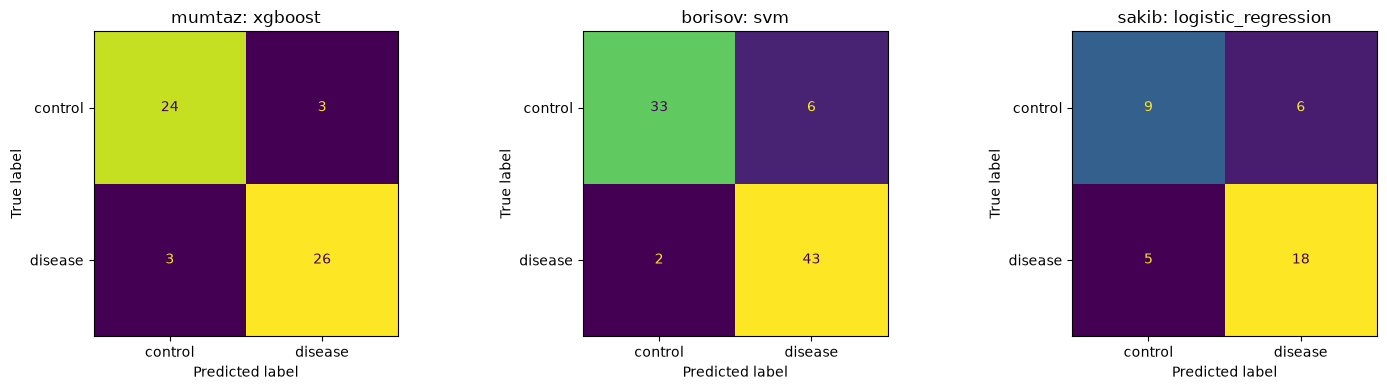

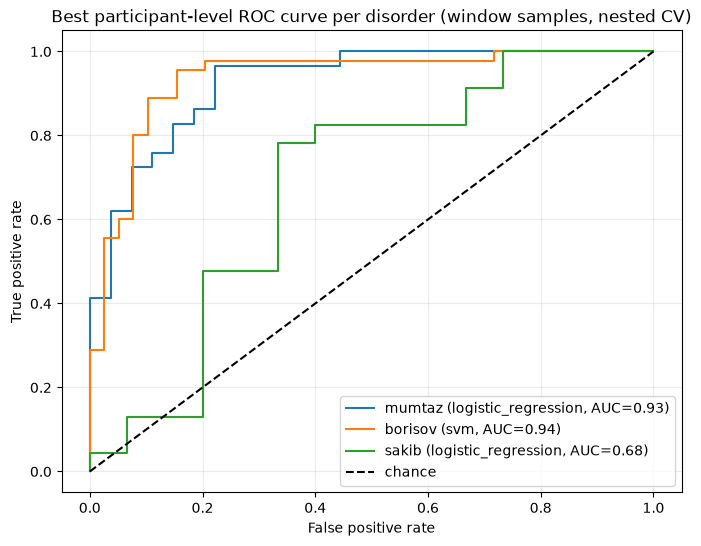

In [13]:
fig, axes = plt.subplots(1, len(TASK_NAMES), figsize=(15, 4))
for ax, dataset in zip(axes, TASK_NAMES):
    best = window_metrics[window_metrics.dataset == dataset].sort_values(
        'balanced_accuracy', ascending=False).iloc[0].model
    y_true, y_pred, y_prob = window_evaluation[dataset][best]
    ConfusionMatrixDisplay.from_predictions(
        y_true, y_pred, display_labels=['control', 'disease'], ax=ax, colorbar=False)
    ax.set_title(f'{dataset}: {best}')
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 6))
for dataset in TASK_NAMES:
    best = window_metrics[window_metrics.dataset == dataset].sort_values(
        'roc_auc', ascending=False).iloc[0].model
    y_true, y_pred, y_prob = window_evaluation[dataset][best]
    fpr, tpr, _ = roc_curve(y_true, y_prob)
    plt.plot(fpr, tpr, label=f'{dataset} ({best}, AUC={roc_auc_score(y_true, y_prob):.2f})')
plt.plot([0, 1], [0, 1], 'k--', label='chance')
plt.xlabel('False positive rate')
plt.ylabel('True positive rate')
plt.title('Best participant-level ROC curve per disorder (window samples, nested CV)')
plt.legend()
plt.grid(alpha=0.25)
plt.show()


In [14]:
# Baseline (participant rows, default hyperparameters) -> tuned participant rows -> tuned window samples
keys = ['dataset', 'model']
columns = keys + ['balanced_accuracy', 'roc_auc']
comparison = (metrics[columns].rename(columns={'balanced_accuracy': 'ba_baseline', 'roc_auc': 'auc_baseline'})
    .merge(participant_tuned_metrics[columns].rename(columns={'balanced_accuracy': 'ba_tuned', 'roc_auc': 'auc_tuned'}), on=keys, how='right')
    .merge(window_metrics[columns].rename(columns={'balanced_accuracy': 'ba_windows', 'roc_auc': 'auc_windows'}), on=keys, how='right'))
comparison.sort_values(keys).round(3)


,dataset,model,ba_baseline,auc_baseline,ba_tuned,auc_tuned,ba_windows,auc_windows
9,borisov,knn,NaN,NaN,0.593,0.612,0.812,0.889
10,borisov,lda,0.579,0.597,0.618,0.655,0.844,0.910
13,borisov,lightgbm,0.648,0.625,0.592,0.595,0.877,0.932
7,borisov,logistic_regression,0.545,0.614,0.635,0.655,0.858,0.914
11,borisov,random_forest,0.615,0.629,0.602,0.644,0.864,0.924
8,borisov,svm,0.647,0.647,0.585,0.617,0.901,0.936
12,borisov,xgboost,0.619,0.647,0.615,0.652,0.851,0.925
2,mumtaz,knn,NaN,NaN,0.657,0.693,0.822,0.898
3,mumtaz,lda,0.661,0.719,0.673,0.712,0.819,0.920
6,mumtaz,lightgbm,0.729,0.792,0.674,0.716,0.856,0.885


## SHAP explanations

For each dataset the best model (balanced accuracy, ties broken by AUC, from the window-level table above) is refitted on all participants of that dataset with the same grouped randomized search, then explained with SHAP (`shap_analysis.py`). Positive SHAP values push a window towards the disease class.

- These explanations describe what the fitted model relies on; they say nothing about generalization, which the nested cross-validation measures. Windows of one participant are correlated, so read the rankings as indicative.
- Units differ by model (log-odds for XGBoost, LightGBM, logistic regression and LDA; probability for random forest), so compare features within a model, not across datasets.
- Tree models and linear models use exact explainers. kNN and non-linear SVMs fall back to the slow `KernelExplainer` on 100 windows.
- SHAP interactions are only available for tree models. If a dataset's best model is not a tree model, its best tree model is explained instead.
- Features are named `channel_band_measure`, so importances are also summed by band, measure and channel.


In [15]:
import numpy
import scipy
import scipy.spatial
import model_tuning
import shap
import shap_analysis as sa

/home/ulaval.ca/kebel33/.local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [16]:
SHAP_MAX_ROWS = 1500  # windows explained per dataset (random subsample when there are more)

def best_model(dataset, only=None):
    ranked = window_metrics[window_metrics.dataset == dataset]
    if only is not None:
        ranked = ranked[ranked.model.isin(only)]
    return ranked.sort_values(['balanced_accuracy', 'roc_auc'], ascending=False).iloc[0].model

def fit_for_shap(dataset, model_name):
    subset = window_features[window_features.dataset == dataset].dropna(axis=1, how='all')
    columns = [c for c in subset if c.startswith('ch')]
    pipeline, inner_auc, _ = sa.fit_final_model(
        subset, columns, model_name, TUNED_MODELS, profile=TUNING_PROFILE, n_jobs=SEARCH_JOBS)
    data = sa.transform(pipeline, subset, columns, max_samples=SHAP_MAX_ROWS)
    return pipeline, data, inner_auc

shap_results = {}
for dataset in TASK_NAMES:
    model_name = best_model(dataset)
    pipeline, data, inner_auc = fit_for_shap(dataset, model_name)
    values, rows = sa.explain(pipeline, model_name, data)
    shap_results[dataset] = dict(model=model_name, pipeline=pipeline, data=data, values=values, rows=rows)
    print(f'{dataset}: {model_name}, inner AUC {inner_auc:.3f}, {rows.shape[1]} features kept, {len(rows)} windows explained')

shap_importance = pd.concat([
    sa.feature_importance(r['values'], list(r['rows'].columns)).assign(dataset=dataset, model=r['model'])
    for dataset, r in shap_results.items()], ignore_index=True)
shap_importance.to_csv(OUTPUTS / 'shap_feature_importance.csv', index=False)
shap_importance.groupby('dataset').head(10)


mumtaz: xgboost, inner AUC 0.923, 855 features kept, 1500 windows explained
borisov: svm, inner AUC 0.926, 720 features kept, 100 windows explained
sakib: logistic_regression, inner AUC 0.694, 630 features kept, 1140 windows explained


,feature,mean_abs_shap,channel,band,measure,dataset,model
0,ch19_gamma_LogPower,0.755904,ch19,gamma,LogPower,mumtaz,xgboost
1,ch08_gamma_FuzzyEn,0.585246,ch08,gamma,FuzzyEn,mumtaz,xgboost
2,ch05_beta_RelPower,0.447866,ch05,beta,RelPower,mumtaz,xgboost
3,ch18_gamma_LogPower,0.440896,ch18,gamma,LogPower,mumtaz,xgboost
4,ch10_beta_LogPower,0.387102,ch10,beta,LogPower,mumtaz,xgboost
5,ch09_gamma_LogPower,0.359001,ch09,gamma,LogPower,mumtaz,xgboost
6,ch10_theta_RelPower,0.348671,ch10,theta,RelPower,mumtaz,xgboost
7,ch18_gamma_RelPower,0.345200,ch18,gamma,RelPower,mumtaz,xgboost
8,ch12_alpha_RelPower,0.298513,ch12,alpha,RelPower,mumtaz,xgboost
9,ch17_gamma_FuzzyEn,0.272561,ch17,gamma,FuzzyEn,mumtaz,xgboost


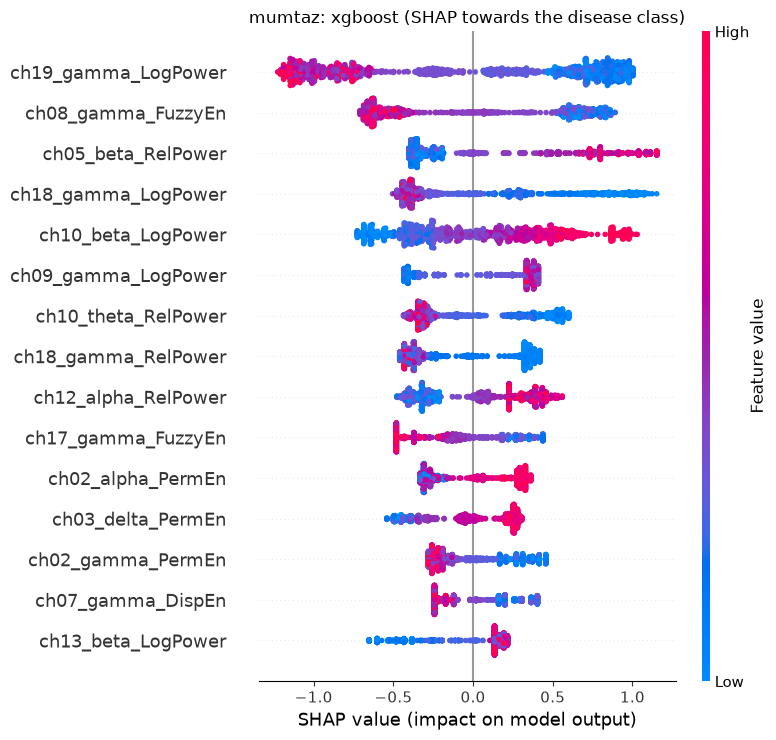

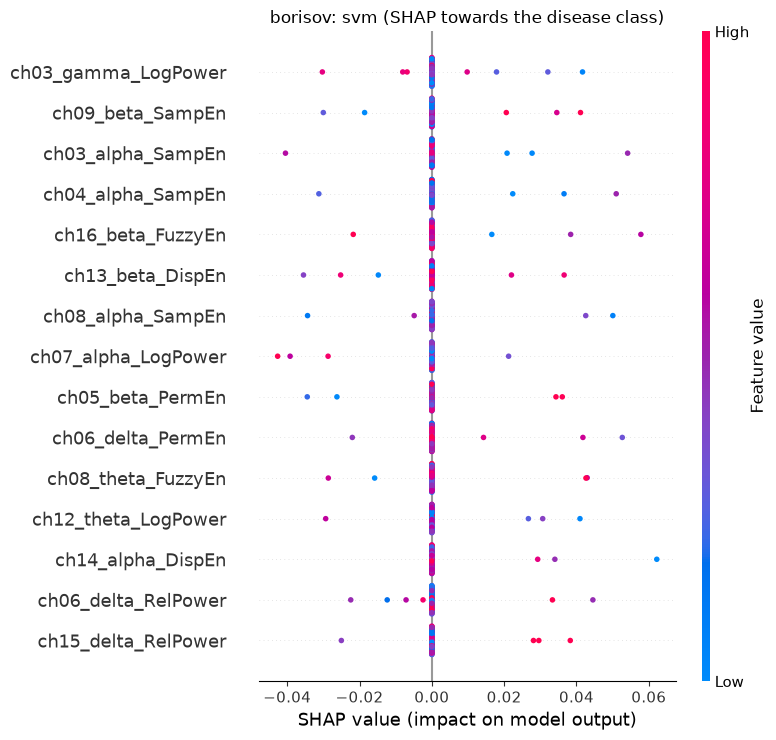

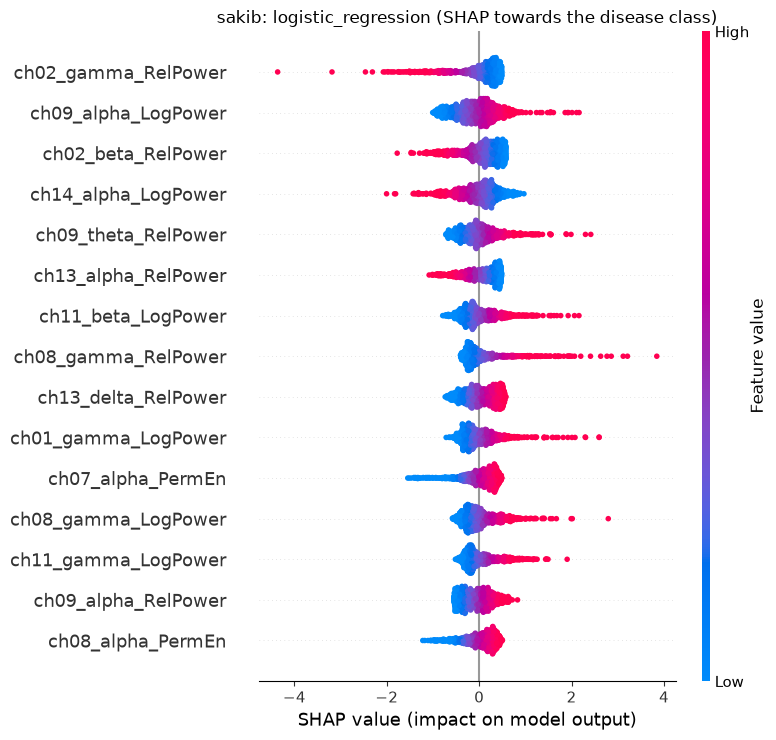

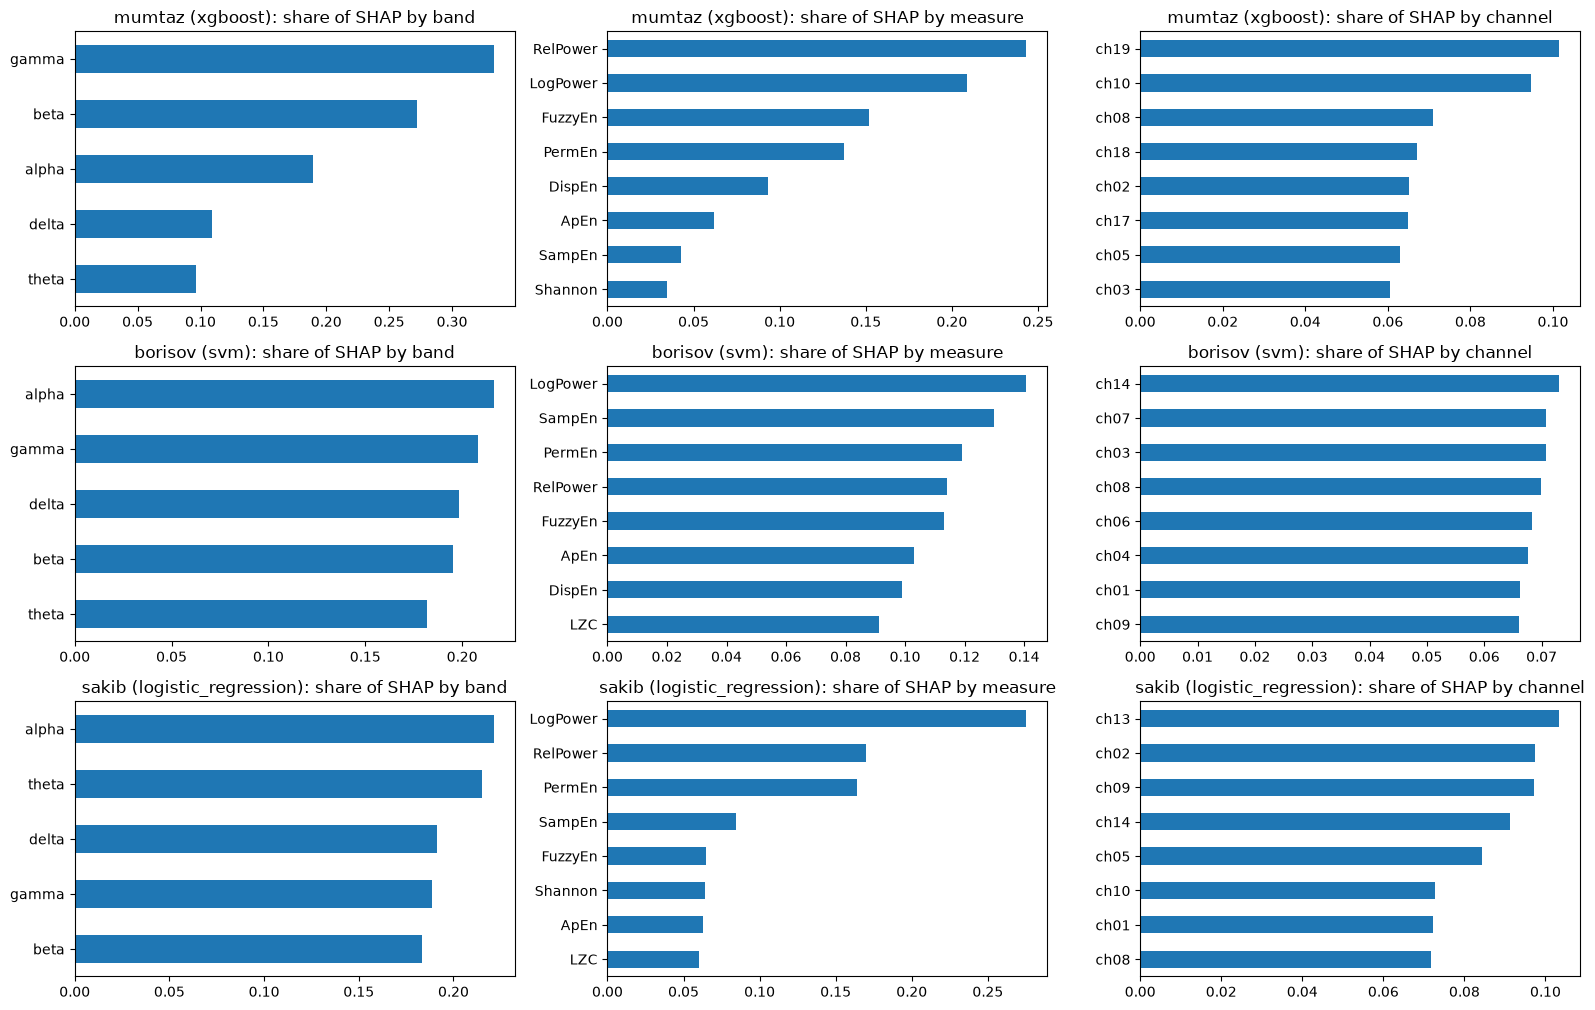

In [17]:
for dataset, r in shap_results.items():
    shap.summary_plot(r['values'], r['rows'], max_display=15, show=False)
    plt.title(f"{dataset}: {r['model']} (SHAP towards the disease class)")
    plt.tight_layout()
    plt.show()

fig, axes = plt.subplots(len(shap_results), 3, figsize=(16, 3.4 * len(shap_results)))
for row, (dataset, r) in zip(axes, shap_results.items()):
    names = list(r['rows'].columns)
    for ax, by in zip(row, ['band', 'measure', 'channel']):
        share = sa.group_importance(r['values'], names, by)
        (share / share.sum()).head(8).iloc[::-1].plot.barh(ax=ax)
        ax.set_title(f'{dataset} ({r["model"]}): share of SHAP by {by}')
plt.tight_layout()
plt.show()


In [18]:
# Interaction tensors have (features x features) values per window, so only a few windows are used
SHAP_INTERACTION_ROWS = 100
interaction_results = {}
for dataset, r in shap_results.items():
    if r['model'] in sa.TREE_MODELS:
        model_name, pipeline, data = r['model'], r['pipeline'], r['data']
    else:
        model_name = best_model(dataset, only=sa.TREE_MODELS)
        pipeline, data, _ = fit_for_shap(dataset, model_name)
    inter, rows = sa.interactions(pipeline, data, max_samples=SHAP_INTERACTION_ROWS)
    interaction_results[dataset] = dict(model=model_name, values=inter, rows=rows)
    print(f'{dataset}: interactions of {model_name} on {len(rows)} windows, {rows.shape[1]} features')

shap_interactions = pd.concat([
    sa.interaction_table(r['values'], list(r['rows'].columns), top=15).assign(dataset=dataset, model=r['model'])
    for dataset, r in interaction_results.items()], ignore_index=True)
shap_interactions.to_csv(OUTPUTS / 'shap_interactions.csv', index=False)
shap_interactions.groupby('dataset').head(8)


mumtaz: interactions of xgboost on 100 windows, 855 features
borisov: interactions of lightgbm on 100 windows, 720 features
sakib: interactions of lightgbm on 100 windows, 630 features


,feature_a,feature_b,mean_abs_interaction,dataset,model
0,ch10_beta_LogPower,ch19_gamma_LogPower,0.132330,mumtaz,xgboost
1,ch07_gamma_DispEn,ch05_beta_RelPower,0.130845,mumtaz,xgboost
2,ch12_alpha_RelPower,ch12_beta_RelPower,0.079394,mumtaz,xgboost
3,ch08_gamma_FuzzyEn,ch05_beta_RelPower,0.075255,mumtaz,xgboost
4,ch13_beta_LogPower,ch18_gamma_LogPower,0.072139,mumtaz,xgboost
5,ch08_gamma_FuzzyEn,ch09_beta_LogPower,0.069575,mumtaz,xgboost
6,ch02_gamma_FuzzyEn,ch14_beta_RelPower,0.066802,mumtaz,xgboost
7,ch17_gamma_FuzzyEn,ch12_theta_LogPower,0.063632,mumtaz,xgboost
15,ch14_gamma_RelPower,ch15_alpha_RelPower,0.144038,borisov,lightgbm
16,ch10_gamma_DispEn,ch14_gamma_RelPower,0.143427,borisov,lightgbm


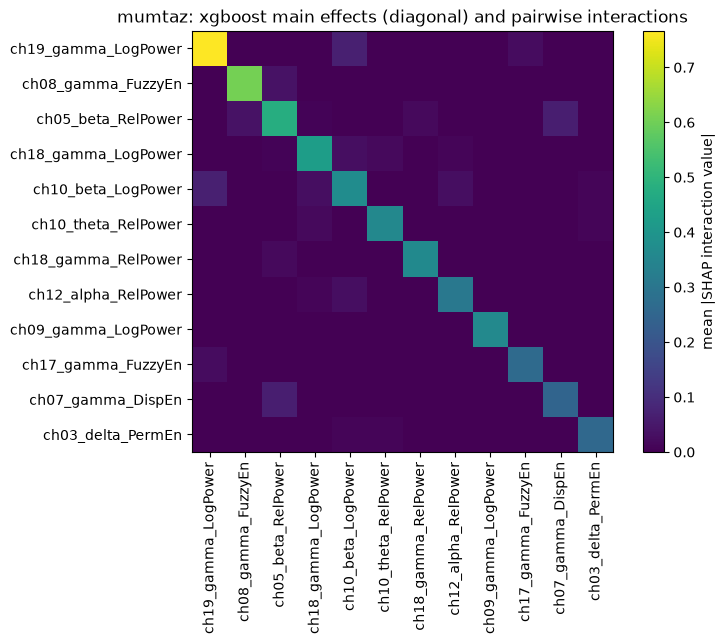

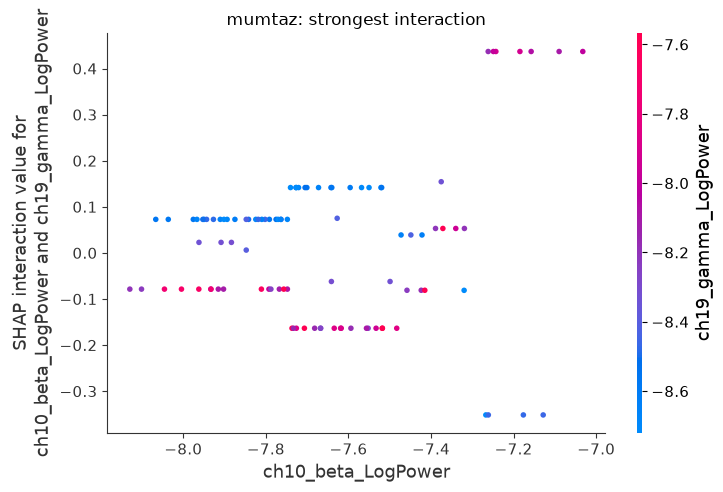

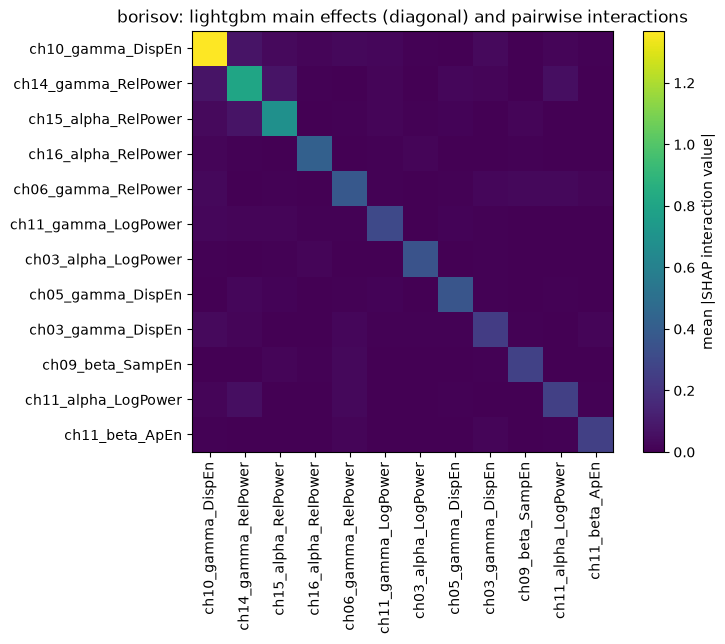

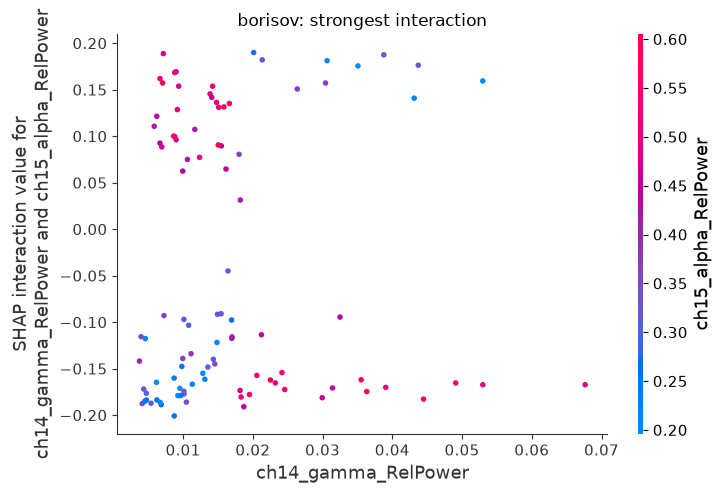

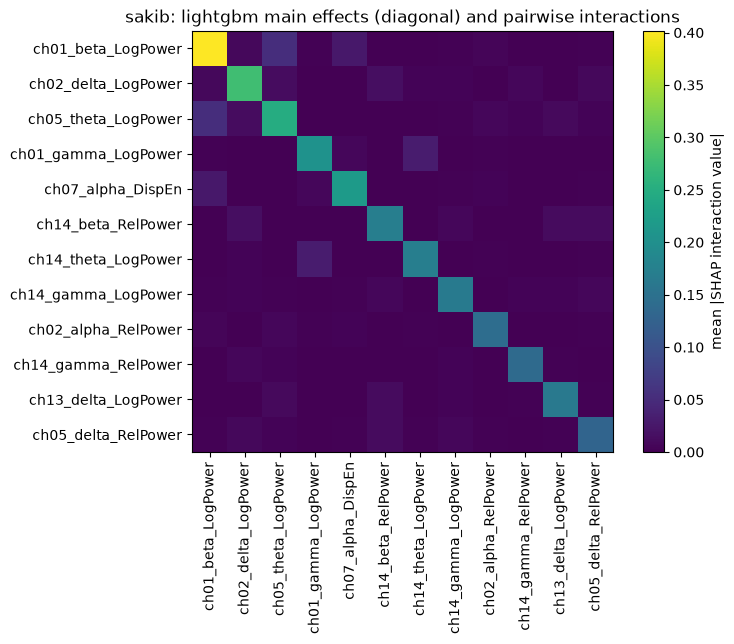

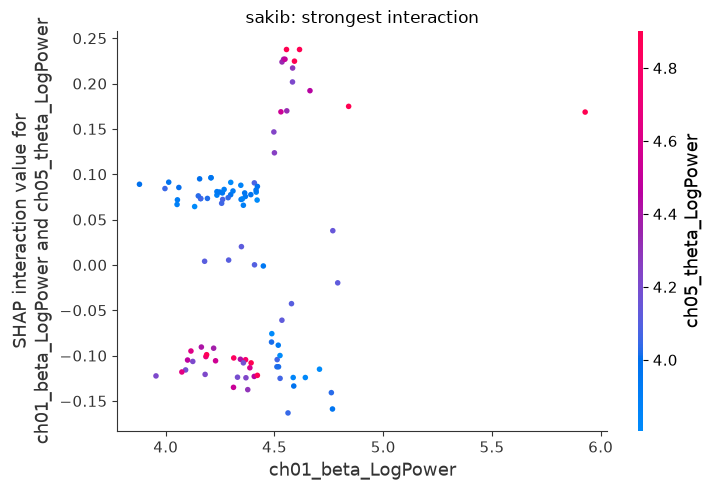

In [19]:
TOP_FEATURES = 12
for dataset, r in interaction_results.items():
    names = np.array(r['rows'].columns)
    strength = np.abs(r['values']).mean(axis=0)  # diagonal: main effects, off-diagonal: interactions
    top = np.argsort(strength.sum(axis=1))[::-1][:TOP_FEATURES]
    plt.figure(figsize=(8, 6.5))
    plt.imshow(strength[np.ix_(top, top)], cmap='viridis')
    plt.colorbar(label='mean |SHAP interaction value|')
    plt.xticks(range(len(top)), names[top], rotation=90)
    plt.yticks(range(len(top)), names[top])
    plt.title(f"{dataset}: {r['model']} main effects (diagonal) and pairwise interactions")
    plt.tight_layout()
    plt.show()

    pair = shap_interactions[shap_interactions.dataset == dataset].iloc[0]
    shap.dependence_plot((pair.feature_a, pair.feature_b), r['values'], r['rows'], show=False)
    plt.title(f'{dataset}: strongest interaction')
    plt.tight_layout()
    plt.show()


## Interpretation and next steps

Metrics are participant-level out-of-fold estimates from nested grouped cross-validation. With 38-84 participants, a difference of a few points between models is within the bootstrap interval (`ba_ci_low` / `ba_ci_high`); `ba_sd_over_repeats` shows split-to-split variation for the participant-level run. The model picked for each plot is the best on the same out-of-fold predictions, so its score is slightly optimistic. The comparison table separates the effect of tuning (baseline vs tuned participant rows) from the effect of window samples (tuned participant rows vs windows). Next steps: toggle `USE_EXTRA_FEATURES` to measure what the extra features add, and check whether the features that SHAP ranks highest are stable across datasets and across repeated fits.
